# Standalone patch notebook (no training, no Flower)
Run the cells **top to bottom** in a fresh Colab session (GPU runtime recommended, but CPU also works, slowly). It only *loads* your saved checkpoints from Google Drive (`/content/drive/My Drive/FedLungProject/`) and your already-extracted dataset folder; nothing is retrained. Setup cells 2-5 are copied unchanged from your main notebook (cells 6, 7, 8, 11). At the end it prints a JSON block: send it to me together with the two PDF figures it saves in the same Drive folder.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q segmentation-models-pytorch albumentations grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
# Set runtime device to leverage the Colab T4 GPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Hardware Device: {DEVICE}")

# Set paths for the rest of the code blocks
DATASET_DIR = '/content/drive/My Drive/FedLungProject/datasets'
IMAGE_DIR = os.path.join(DATASET_DIR, 'Chest-X-Ray/Chest-X-Ray/image')
MASK_DIR = os.path.join(DATASET_DIR, 'Chest-X-Ray/Chest-X-Ray/mask')

Active Hardware Device: cuda


In [4]:
import os
import pandas as pd
import cv2
from torch.utils.data import Dataset

class FederatedLungDataset(Dataset):
    def __init__(self, csv_path, img_dir, mask_dir, county_name, transform=None):
        """
        county_name: 'montgomery' or 'shenzhen'
        """
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.transform = transform

        # Load the index sheet
        df = pd.read_csv(csv_path)

        # Isolate the data into client-specific subsets
        if county_name.lower() == 'montgomery':
            self.filtered_df = df[df['county'].str.lower() == 'montgomery'].reset_index(drop=True)
        elif county_name.lower() == 'shenzhen':
            self.filtered_df = df[df['county'].str.lower().str.contains('shen')].reset_index(drop=True)
        else:
            raise ValueError("Unknown client node name. Select 'montgomery' or 'shenzhen'.")

    def __len__(self):
        return len(self.filtered_df)

    def __getitem__(self, idx):
        # Extract file identifier and force it to be a clean string
        raw_id = self.filtered_df.iloc[idx]['id']
        img_name = str(raw_id)

        # If the index misses the extension, append it automatically
        if not img_name.endswith('.png'):
            img_name = img_name + '.png'

        img_path = os.path.join(self.img_dir, img_name)
        mask_path = os.path.join(self.mask_dir, img_name)

        # Read files using OpenCV
        image = cv2.imread(img_path)
        if image is None:
            raise FileNotFoundError(f"Could not find image at: {img_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) # Force to standard RGB format
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE) # Masks are 1-channel arrays
        if mask is None:
            raise FileNotFoundError(f"Could not find mask at: {mask_path}")

        # Apply transformation matrices simultaneously
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        # Convert mask pixels to a binary float (0.0 or 1.0) and add channel dimension
        mask = (mask > 0).float().unsqueeze(0)

        return image, mask

In [5]:
from torch.utils.data import random_split

# 1. Define configurations for your training transformations
train_transforms = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# Re-verify absolute paths established earlier
DATASET_DIR = '/content/drive/My Drive/FedLungProject/datasets'
CSV_PATH = os.path.join(DATASET_DIR, 'MetaData.csv')
IMAGE_DIR = os.path.join(DATASET_DIR, 'Chest-X-Ray/Chest-X-Ray/image')
MASK_DIR = os.path.join(DATASET_DIR, 'Chest-X-Ray/Chest-X-Ray/mask')

# 2. Build full institutional datasets
full_client0_dataset = FederatedLungDataset(CSV_PATH, IMAGE_DIR, MASK_DIR, 'montgomery', transform=train_transforms)
full_client1_dataset = FederatedLungDataset(CSV_PATH, IMAGE_DIR, MASK_DIR, 'shenzhen', transform=train_transforms)

# 3. Create rigorous 80/20 train/validation splits per client node
c0_train_len = int(len(full_client0_dataset) * 0.8)
c0_val_len = len(full_client0_dataset) - c0_train_len
client0_train_set, client0_val_set = random_split(full_client0_dataset, [c0_train_len, c0_val_len], generator=torch.Generator().manual_seed(42))

c1_train_len = int(len(full_client1_dataset) * 0.8)
c1_val_len = len(full_client1_dataset) - c1_train_len
client1_train_set, client1_val_set = random_split(full_client1_dataset, [c1_train_len, c1_val_len], generator=torch.Generator().manual_seed(42))

# 4. Initialize isolated DataLoaders
client0_train_loader = DataLoader(client0_train_set, batch_size=8, shuffle=True)
client0_val_loader = DataLoader(client0_val_set, batch_size=8, shuffle=False)

client1_train_loader = DataLoader(client1_train_set, batch_size=8, shuffle=True)
client1_val_loader = DataLoader(client1_val_set, batch_size=8, shuffle=False)

print("--- Data Split Audit Complete ---")
print(f"✓ Client 0 (Montgomery) -> Train Patches: {len(client0_train_set)}, Val Patches: {len(client0_val_set)}")
print(f"✓ Client 1 (Shenzhen)   -> Train Patches: {len(client1_train_set)}, Val Patches: {len(client1_val_set)}")

--- Data Split Audit Complete ---
✓ Client 0 (Montgomery) -> Train Patches: 110, Val Patches: 28
✓ Client 1 (Shenzhen)   -> Train Patches: 452, Val Patches: 114


In [6]:
#10

import torch
import torch.nn as nn
import torchvision.models as models
import torch.nn.functional as F

class TransformerBottleneck(nn.Module):
    """
    Vision Transformer bottleneck layer designed to capture long-range global contexts
    and explicitly extract inner self-attention maps for XAI validation checks.
    """
    def __init__(self, in_channels, dim=512, num_heads=8, depth=1):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads

        # Project spatial grids to transformer token dimensions
        self.proj = nn.Conv2d(in_channels, dim, kernel_size=1)

        # Multi-Head Attention layers
        self.attn_layers = nn.ModuleList([
            nn.MultiheadAttention(embed_dim=dim, num_heads=num_heads, batch_first=True)
            for _ in range(depth)
        ])
        self.ln = nn.LayerNorm(dim)
        self.unproj = nn.Conv2d(dim, in_channels, kernel_size=1)

        # Target placeholder to store captured XAI attention arrays
        self.extracted_attention_maps = None

    def forward(self, x):
        B, C, H, W = x.shape
        feat = self.proj(x) # Shape: [B, dim, H, W]
        feat = feat.flatten(2).permute(0, 2, 1) # Reshape to sequence tokens: [B, H*W, dim]

        out = feat
        for attn in self.attn_layers:
            # Extract and store attention weights matrix (Q x K^T) during runtime
            attn_out, attn_weights = attn(
    self.ln(out),
    self.ln(out),
    self.ln(out),
    need_weights=True,
    average_attn_weights=False
)
            out = out + attn_out
            self.extracted_attention_maps = attn_weights # Matrix size: [B, H*W, H*W]

        out = out.permute(0, 2, 1).reshape(B, self.dim, H, W)
        return self.unproj(out)

class TransUNetMini(nn.Module):
    """
    Hybrid CNN-Transformer network architecture that integrates a pre-trained ResNet
    encoder backbone with a Vision Transformer bottleneck and a convolutional decoder.
    """
    def __init__(self):
        super().__init__()
        # 1. Base Encoder Architecture
        base_resnet = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
        self.init_conv = nn.Sequential(base_resnet.conv1, base_resnet.bn1, base_resnet.relu, base_resnet.maxpool)

        # Skip Connection Layers
        self.layer1 = base_resnet.layer1 # Output: 64 channels
        self.layer2 = base_resnet.layer2 # Output: 128 channels
        self.layer3 = base_resnet.layer3 # Output: 256 channels
        self.layer4 = base_resnet.layer4 # Output: 512 channels

        # 2. Vision Transformer Core Bottleneck
        self.vit_bottleneck = TransformerBottleneck(in_channels=512, dim=512, num_heads=8)

        # 3. Convolutional Decoder Network
        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec_conv1 = nn.Sequential(nn.Conv2d(512, 256, kernel_size=3, padding=1), nn.ReLU(inplace=True))

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec_conv2 = nn.Sequential(nn.Conv2d(256, 128, kernel_size=3, padding=1), nn.ReLU(inplace=True))

        self.up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec_conv3 = nn.Sequential(nn.Conv2d(128, 64, kernel_size=3, padding=1), nn.ReLU(inplace=True))

        self.up4 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec_conv4 = nn.Sequential(nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.ReLU(inplace=True))

        # Final Segmentation Output Projection Map
        self.final_mask_projection = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        # Encoder Pass with Skip Connection Registrations
        x0 = self.init_conv(x)      # Shape: [B, 64, 56, 56]
        x1 = self.layer1(x0)        # Shape: [B, 64, 56, 56]
        x2 = self.layer2(x1)        # Shape: [B, 128, 28, 28]
        x3 = self.layer3(x2)        # Shape: [B, 256, 14, 14]
        x4 = self.layer4(x3)        # Shape: [B, 512, 7, 7]

        # Transformer Bottleneck Pass
        b_out = self.vit_bottleneck(x4) # Shape: [B, 512, 7, 7]

        # Decoder Pass with Skip Connection Merges
        d1 = self.up1(b_out)
        d1 = torch.cat([d1, x3], dim=1) # Target Grid Size: 14x14
        d1 = self.dec_conv1(d1)

        d2 = self.up2(d1)
        d2 = torch.cat([d2, x2], dim=1) # Target Grid Size: 28x28
        d2 = self.dec_conv2(d2)

        d3 = self.up3(d2)
        d3 = torch.cat([d3, x1], dim=1) # Target Grid Size: 56x56
        d3 = self.dec_conv3(d3)

        d4 = self.up4(d3) # Upsamples to 112x112 spatial footprint
        d4 = self.dec_conv4(d4)

        # Upsample directly to match original input size (224x224)
        d5 = F.interpolate(d4, scale_factor=2, mode='bilinear', align_corners=True)

        return self.final_mask_projection(d5)

# Initialize and assign the model to your hardware accelerator
MODEL = TransUNetMini().to(DEVICE)

# 4. Standard Medical Cost Evaluation Functions
import segmentation_models_pytorch as smp
dice_loss = smp.losses.DiceLoss(mode='binary')
bce_loss = nn.BCEWithLogitsLoss()

def compute_loss(predictions, targets):
    return bce_loss(predictions, targets) + dice_loss(predictions, targets)

def compute_dice_coefficient(preds, targets, threshold=0.5):
    preds = (torch.sigmoid(preds) > threshold).float()
    intersection = (preds * targets).sum()
    total = preds.sum() + targets.sum()
    if total == 0:
        return 1.0
    return (2. * intersection) / total

print("✓ Custom TransUNet compiled successfully with embedded XAI hooks.")

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 164MB/s]


✓ Custom TransUNet compiled successfully with embedded XAI hooks.


In [7]:
# metric helpers (copied from main notebook cells 43 and 83, without the training loop)
import torch.optim as optim
from torch.utils.data import ConcatDataset, DataLoader
def compute_iou(preds, targets, threshold=0.5):
    preds = (torch.sigmoid(preds) > threshold).float()
    intersection = (preds * targets).sum()
    union = preds.sum() + targets.sum() - intersection
    return 1.0 if union == 0 else (intersection / union).item()

@torch.no_grad()
def evaluate_full(model, loader, device):
    model.eval()
    dice_sum, iou_sum, n = 0.0, 0.0, 0
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        outputs = model(images)
        dice_sum += compute_dice_coefficient(outputs, masks).item() * images.size(0)
        iou_sum  += compute_iou(outputs, masks) * images.size(0)
        n += images.size(0)
    return dice_sum / n, iou_sum / n

@torch.no_grad()
def per_sample_dice(model, loader, device):
    model.eval(); dices = []
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        preds = (torch.sigmoid(model(images)) > 0.5).float()
        for i in range(images.size(0)):
            inter = (preds[i] * masks[i]).sum()
            dices.append((2*inter / (preds[i].sum() + masks[i].sum() + 1e-8)).item())
    return dices

pooled_val_loader = DataLoader(ConcatDataset([client0_val_set, client1_val_set]), batch_size=8, shuffle=False)
CENTRAL_MODEL = TransUNetMini().to(DEVICE)
CK="/content/drive/My Drive/FedLungProject/"
def load(m, name): m.load_state_dict(torch.load(CK+name, map_location=DEVICE)); m.eval(); return m
# sanity check: must print about 0.9600 and 0.9232
print("sanity check round 15:", evaluate_full(load(MODEL,"global_model_round_15.pth"), pooled_val_loader, DEVICE))

sanity check round 15: (0.959975584292076, 0.9232194096269742)


## Patch cells

In [8]:
# 1. Chance level for the in-mask fraction: fraction of the 224x224 image covered by the lung mask
import numpy as np, torch
from torch.utils.data import ConcatDataset, DataLoader
areas=[]
for _,m in ConcatDataset([client0_val_set, client1_val_set]):
    areas.append(float(m.mean()))
lung_frac=float(np.mean(areas)); print("mean lung-area fraction of image:", round(lung_frac,4))
print("LaTeX sentence:", r"For reference, a spatially uniform map would obtain $f=%.3f$ (the mean lung-area fraction of the validation images)." % lung_frac)

mean lung-area fraction of image: 0.2516
LaTeX sentence: For reference, a spatially uniform map would obtain $f=0.252$ (the mean lung-area fraction of the validation images).


In [9]:
RES={}
import cv2
from pytorch_grad_cam import GradCAMPlusPlus
# --- Grad-CAM (same procedure as main notebook cells 74/86) for dec2 and dec4 ---
def gradcam_mass(model, layer, loader):
    st={}
    h1=layer.register_forward_hook(lambda m,i,o: st.__setitem__('a',o))
    h2=layer.register_full_backward_hook(lambda m,gi,go: st.__setitem__('g',go[0]))
    model.eval(); sc=[]
    for images,masks in loader:
        for i in range(images.size(0)):
            x=images[i:i+1].to(DEVICE).requires_grad_(True); gt=masks[i,0].numpy()
            out=model(x); model.zero_grad(); out.sum().backward()
            a=st['a'][0].detach().cpu().numpy(); g=st['g'][0].detach().cpu().numpy()
            cam=np.maximum((g.mean(axis=(1,2))[:,None,None]*a).sum(axis=0),0)
            cam=cv2.resize(cam,(224,224),interpolation=cv2.INTER_CUBIC); cam=(cam-cam.min())/(cam.max()-cam.min()+1e-8)
            sc.append((cam*gt).sum()/(cam.sum()+1e-8))
    h1.remove(); h2.remove(); return float(np.mean(sc))
class MaskTarget:
    def __init__(self, m): self.m=m
    def __call__(self, out): return (torch.sigmoid(out)*self.m.to(out.device)).sum()
def gradcampp_mass(model, layer, loader):
    model.eval(); cam=GradCAMPlusPlus(model=model, target_layers=[layer]); sc=[]
    for images,masks in loader:
        for i in range(images.size(0)):
            x=images[i:i+1].to(DEVICE); gt=masks[i:i+1].to(DEVICE)
            g=cam(input_tensor=x, targets=[MaskTarget(gt)])[0]
            g=cv2.resize(g,(224,224),interpolation=cv2.INTER_CUBIC); g=(g-g.min())/(g.max()-g.min()+1e-8)
            sc.append((g*masks[i,0].numpy()).sum()/(g.sum()+1e-8))
    return float(np.mean(sc))
R=[3,5,10,15]; gc={"dec2":[],"dec4":[]}; pp={"dec2":[],"dec4":[]}
for r in R:
    load(MODEL,f"global_model_round_{r}.pth")
    gc["dec2"].append(gradcam_mass(MODEL,MODEL.dec_conv2,pooled_val_loader)); gc["dec4"].append(gradcam_mass(MODEL,MODEL.dec_conv4,pooled_val_loader))
    pp["dec2"].append(gradcampp_mass(MODEL,MODEL.dec_conv2,pooled_val_loader)); pp["dec4"].append(gradcampp_mass(MODEL,MODEL.dec_conv4,pooled_val_loader))
print("Grad-CAM:",gc); print("Grad-CAM++:",pp)
RES["gradcam_dec2_in_mask"]=gc["dec2"]; RES["gradcam_dec4_in_mask"]=gc["dec4"]; RES["gradcampp_true"]=pp

Grad-CAM: {'dec2': [0.6761564016342163, 0.6595147848129272, 0.6735813617706299, 0.6744953393936157], 'dec4': [0.8063005208969116, 0.798453688621521, 0.7924498915672302, 0.7947834730148315]}
Grad-CAM++: {'dec2': [0.7649545073509216, 0.7412387728691101, 0.742733895778656, 0.7566460371017456], 'dec4': [0.9610892534255981, 0.9795525670051575, 0.9827377796173096, 0.9825097918510437]}


In [10]:
# 3. Per-client round-15 metrics (4 d.p.)
MODEL.load_state_dict(torch.load("/content/drive/My Drive/FedLungProject/global_model_round_15.pth", map_location=DEVICE))
mc=evaluate_full(MODEL, client0_val_loader, DEVICE); sz=evaluate_full(MODEL, client1_val_loader, DEVICE)
print("Montgomery (Dice, IoU):", mc, " Shenzhen:", sz)
RES["per_client_round15"]={"montgomery_n28":{"dice":mc[0],"iou":mc[1]},"shenzhen_n114":{"dice":sz[0],"iou":sz[1]}}

Montgomery (Dice, IoU): (0.9633586832455227, 0.9293660351208278)  Shenzhen: (0.9591911529239855, 0.9218637368135285)


In [11]:
# 4. Per-seed values with 4+ decimals, population and sample SD, from the saved seed checkpoints
sd=[]; si=[]
for s in [0,1,2]:
    m=TransUNetMini().to(DEVICE); m.load_state_dict(torch.load(f"/content/drive/My Drive/FedLungProject/seed{s}_round_15.pth", map_location=DEVICE))
    d,i=evaluate_full(m, pooled_val_loader, DEVICE); sd.append(d); si.append(i)
print("Dice:",sd,"IoU:",si)
print("Dice mean %.4f pop-SD %.4f sample-SD %.4f"%(np.mean(sd),np.std(sd),np.std(sd,ddof=1)))
print("IoU  mean %.4f pop-SD %.4f sample-SD %.4f"%(np.mean(si),np.std(si),np.std(si,ddof=1)))
RES["seeds"]={"dice":sd,"iou":si}

Dice: [0.9587940170731343, 0.959445704037035, 0.9596331614843556] IoU: [0.9210658031450191, 0.9222706875330965, 0.9226487555973967]
Dice mean 0.9593 pop-SD 0.0004 sample-SD 0.0004
IoU  mean 0.9220 pop-SD 0.0007 sample-SD 0.0008


In [12]:
# paired bootstrap: federated vs centralized (per-image Dice, pooled validation set)
fed=np.array(per_sample_dice(load(MODEL,"global_model_round_15.pth"), pooled_val_loader, DEVICE))
cen=np.array(per_sample_dice(load(CENTRAL_MODEL,"centralized_model_final.pth"), pooled_val_loader, DEVICE))
diff=cen-fed; rng=np.random.default_rng(0); bs=[rng.choice(diff,len(diff)).mean() for _ in range(10000)]
print("per-image Dice fed %.4f cen %.4f; centralized-minus-federated %.4f, 95%% CI [%.4f, %.4f]"%(fed.mean(),cen.mean(),diff.mean(),*np.percentile(bs,[2.5,97.5])))
RES["bootstrap_central_minus_fed_dice"]={"mean":float(diff.mean()),"ci95":[float(x) for x in np.percentile(bs,[2.5,97.5])]}

per-image Dice fed 0.9596 cen 0.9602; centralized-minus-federated 0.0006, 95% CI [-0.0011, 0.0022]


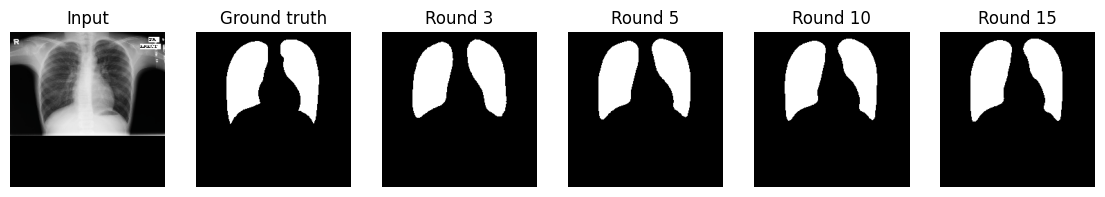

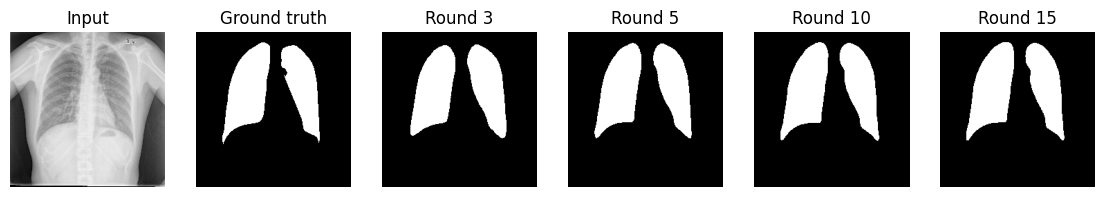

In [13]:
# 6. Regenerate qualitative Figures 3 and 5 with correctly de-normalised inputs, 300 dpi
import matplotlib.pyplot as plt
MEAN=np.array([0.485,0.456,0.406]); STD=np.array([0.229,0.224,0.225])
def qual_fig(dataset, idx, fname, rounds=(3,5,10,15)):
    img,mask=dataset[idx]; x=img.unsqueeze(0).to(DEVICE)
    rgb=np.clip(img.permute(1,2,0).numpy()*STD+MEAN,0,1)
    fig,ax=plt.subplots(1,2+len(rounds),figsize=(14,2.8))
    ax[0].imshow(rgb); ax[0].set_title("Input"); ax[1].imshow(mask.squeeze(),cmap="gray"); ax[1].set_title("Ground truth")
    for k,r in enumerate(rounds):
        MODEL.load_state_dict(torch.load(f"/content/drive/My Drive/FedLungProject/global_model_round_{r}.pth", map_location=DEVICE)); MODEL.eval()
        with torch.no_grad(): p=(torch.sigmoid(MODEL(x))>0.5).float().cpu()[0,0]
        ax[2+k].imshow(p,cmap="gray"); ax[2+k].set_title(f"Round {r}")
    for a in ax: a.axis("off")
    fig.savefig(f"/content/drive/My Drive/FedLungProject/{fname}", dpi=300, bbox_inches="tight"); plt.show()
qual_fig(client0_val_set,0,"Figure_3.pdf")   # Montgomery (same sample index as before)
qual_fig(client1_val_set,0,"Figure_5.pdf")   # Shenzhen

In [14]:
# 7. Export everything and print it -> send me this JSON
import json
print(json.dumps(RES, indent=1))
json.dump(RES, open("/content/drive/My Drive/FedLungProject/patch_results.json","w"), indent=1)

{
 "gradcam_dec2_in_mask": [
  0.6761564016342163,
  0.6595147848129272,
  0.6735813617706299,
  0.6744953393936157
 ],
 "gradcam_dec4_in_mask": [
  0.8063005208969116,
  0.798453688621521,
  0.7924498915672302,
  0.7947834730148315
 ],
 "gradcampp_true": {
  "dec2": [
   0.7649545073509216,
   0.7412387728691101,
   0.742733895778656,
   0.7566460371017456
  ],
  "dec4": [
   0.9610892534255981,
   0.9795525670051575,
   0.9827377796173096,
   0.9825097918510437
  ]
 },
 "per_client_round15": {
  "montgomery_n28": {
   "dice": 0.9633586832455227,
   "iou": 0.9293660351208278
  },
  "shenzhen_n114": {
   "dice": 0.9591911529239855,
   "iou": 0.9218637368135285
  }
 },
 "seeds": {
  "dice": [
   0.9587940170731343,
   0.959445704037035,
   0.9596331614843556
  ],
  "iou": [
   0.9210658031450191,
   0.9222706875330965,
   0.9226487555973967
  ]
 },
 "bootstrap_central_minus_fed_dice": {
  "mean": 0.0005707765968752579,
  "ci95": [
   -0.0011025281229489286,
   0.0022086767558480644
  ]
